In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
import seaborn as sns
import matplotlib.pyplot as plt

In [36]:
class PINN(nn.Module):
    def __init__(self):
        super(PINN,self).__init__()
        self.net = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
            )
    def forward(self,x):
        return self.net(x)
    

In [37]:
def initial_condition(x,y):
    return torch.sin(torch.pi * x) * torch.sin(torch.pi * y)

def boundary_condition(x,y,t, custom_value):
    return torch.full_like(x, custom_value)

In [38]:
def generate_training_data(num_points):
    x = torch.rand(num_points, 1, requires_grad=True)
    y = torch.rand(num_points, 1, requires_grad=True)
    t = torch.rand(num_points, 1, requires_grad=True)

    return x,y,t

In [39]:
def generate_boundary_points(num_points):
    x_boundary = torch.tensor([0.0,1.0]).repeat(num_points//2)
    y_boundary = torch.rand(num_points)

    if torch.rand(1) > 0.5:
        x_boundary, y_boundary = y_boundary, x_boundary

    return x_boundary.view(-1,1), y_boundary.view(-1,1)

def generate_boundary_training_data(num_points):
    x_boundary, y_boundary = generate_boundary_points(num_points)
    t = torch.rand(num_points, 1, requires_grad=True)

    return x_boundary, y_boundary, t


In [40]:
def pde(x, y, t, model):
    input_data = torch.cat([x,y,t],dim=1)
    u = model(input_data)
    u_x, u_y = torch.autograd.grad(u, [x,y], grad_outputs=torch.ones_like(u), create_graph=True, retain_graph=True)
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True, retain_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, grad_outputs=torch.ones_like(u_y), create_graph=True, retain_graph=True)[0]
    u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True, retain_graph=True)[0]
    heat_eq_residual = 1 * u_xx + 1 * u_yy - u_t
    return heat_eq_residual

In [41]:
def train_PINN(model, num_iterations, num_points):
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    for iteration in range(num_iterations):
        optimizer.zero_grad()

        x,y,t = generate_training_data(num_points)

        x_b, y_b, t_b = generate_boundary_training_data(num_points)

        t_initial = torch.zeros_like(t)
        u_initial = initial_condition(x,y)

        custom_value = 0
        u_boundary_x = boundary_condition(x_b, y_b, t_b, custom_value)
        u_boundary_y = boundary_condition(y_b, x_b, t_b, custom_value)

        residual = pde(x,y,t,model)

        loss = nn.MSELoss()(u_initial, model(torch.cat([x,y,t_initial], dim=1))) + \
            nn.MSELoss()(u_boundary_x, model(torch.cat([x_b, y_b, t_b], dim=1))) + \
                nn.MSELoss()(u_boundary_y, model(torch.cat([y_b, x_b, t_b], dim=1))) + \
                    nn.MSELoss()(residual, torch.zeros_like(residual))

        loss.backward()
        optimizer.step()

        if iteration % 100 == 0:
            print("iteration", iteration, "loss", loss)
        
        

In [42]:
model = PINN()
num_iterations = 10000
num_points = 1000
train_PINN(model, num_iterations, num_points)


iteration 0 loss tensor(0.2384, grad_fn=<AddBackward0>)
iteration 100 loss tensor(0.1301, grad_fn=<AddBackward0>)
iteration 200 loss tensor(0.1243, grad_fn=<AddBackward0>)
iteration 300 loss tensor(0.1018, grad_fn=<AddBackward0>)
iteration 400 loss tensor(0.0900, grad_fn=<AddBackward0>)
iteration 500 loss tensor(0.0762, grad_fn=<AddBackward0>)
iteration 600 loss tensor(0.0689, grad_fn=<AddBackward0>)
iteration 700 loss tensor(0.0615, grad_fn=<AddBackward0>)
iteration 800 loss tensor(0.0573, grad_fn=<AddBackward0>)
iteration 900 loss tensor(0.0523, grad_fn=<AddBackward0>)
iteration 1000 loss tensor(0.0504, grad_fn=<AddBackward0>)
iteration 1100 loss tensor(0.0436, grad_fn=<AddBackward0>)
iteration 1200 loss tensor(0.0435, grad_fn=<AddBackward0>)
iteration 1300 loss tensor(0.0380, grad_fn=<AddBackward0>)
iteration 1400 loss tensor(0.0348, grad_fn=<AddBackward0>)
iteration 1500 loss tensor(0.0333, grad_fn=<AddBackward0>)
iteration 1600 loss tensor(0.0285, grad_fn=<AddBackward0>)
iteration

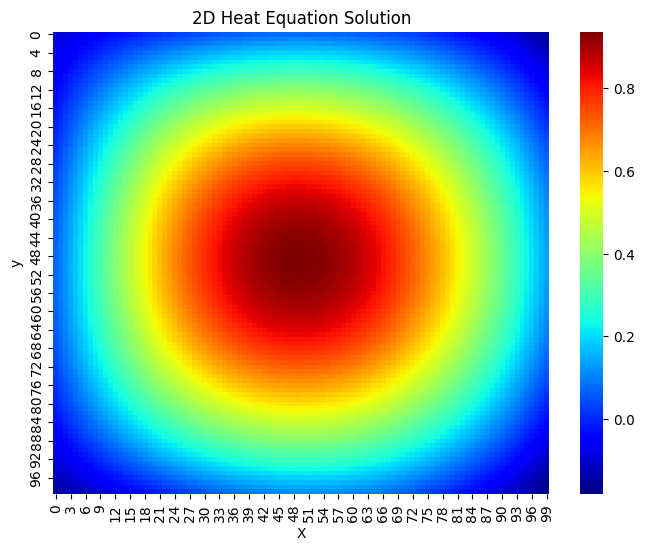

In [43]:
with torch.no_grad():
    x_vals = torch.linspace(0,1,100)
    y_vals = torch.linspace(0,1,100)
    X, Y = torch.meshgrid(x_vals, y_vals)
    t_val = torch.ones_like(X) * 0 # specify the time

    input_data = torch.stack([X.flatten(),Y.flatten(), t_val.flatten()], dim=1)
    solution = model(input_data).reshape(X.shape, Y.shape)

    plt.figure(figsize=(8,6))
    sns.heatmap(solution, cmap="jet")
    plt.title("2D Heat Equation Solution")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.show()

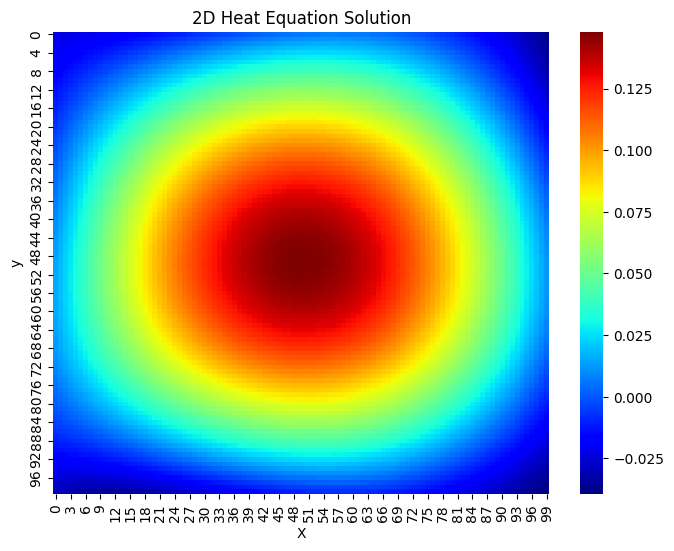

In [44]:
with torch.no_grad():
    x_vals = torch.linspace(0,1,100)
    y_vals = torch.linspace(0,1,100)
    X, Y = torch.meshgrid(x_vals, y_vals)
    t_val = torch.ones_like(X) * 0.1 # specify the time

    input_data = torch.stack([X.flatten(),Y.flatten(), t_val.flatten()], dim=1)
    solution = model(input_data).reshape(X.shape, Y.shape)

    plt.figure(figsize=(8,6))
    sns.heatmap(solution, cmap="jet")
    plt.title("2D Heat Equation Solution")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.show()

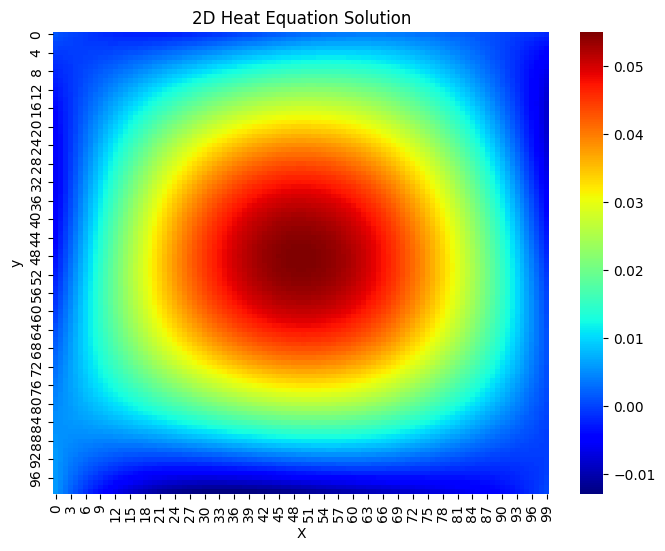

In [45]:
with torch.no_grad():
    x_vals = torch.linspace(0,1,100)
    y_vals = torch.linspace(0,1,100)
    X, Y = torch.meshgrid(x_vals, y_vals)
    t_val = torch.ones_like(X) * 0.15 # specify the time

    input_data = torch.stack([X.flatten(),Y.flatten(), t_val.flatten()], dim=1)
    solution = model(input_data).reshape(X.shape, Y.shape)

    plt.figure(figsize=(8,6))
    sns.heatmap(solution, cmap="jet")
    plt.title("2D Heat Equation Solution")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.show()

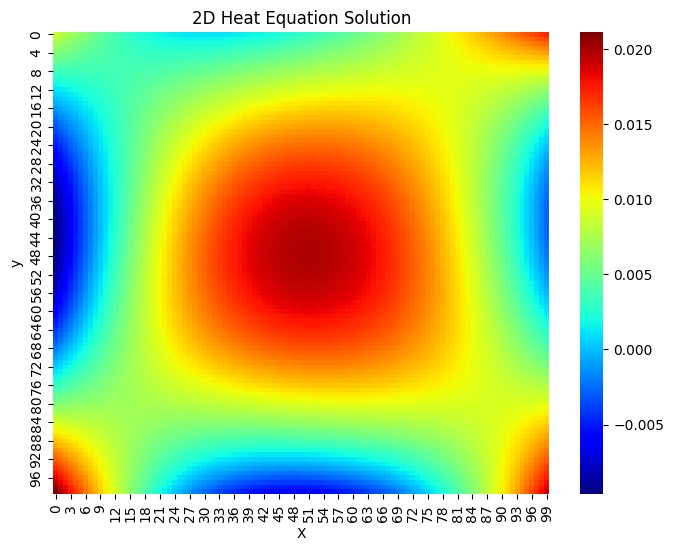

In [46]:
with torch.no_grad():
    x_vals = torch.linspace(0,1,100)
    y_vals = torch.linspace(0,1,100)
    X, Y = torch.meshgrid(x_vals, y_vals)
    t_val = torch.ones_like(X) * 0.2 # specify the time

    input_data = torch.stack([X.flatten(),Y.flatten(), t_val.flatten()], dim=1)
    solution = model(input_data).reshape(X.shape, Y.shape)

    plt.figure(figsize=(8,6))
    sns.heatmap(solution, cmap="jet")
    plt.title("2D Heat Equation Solution")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.show()

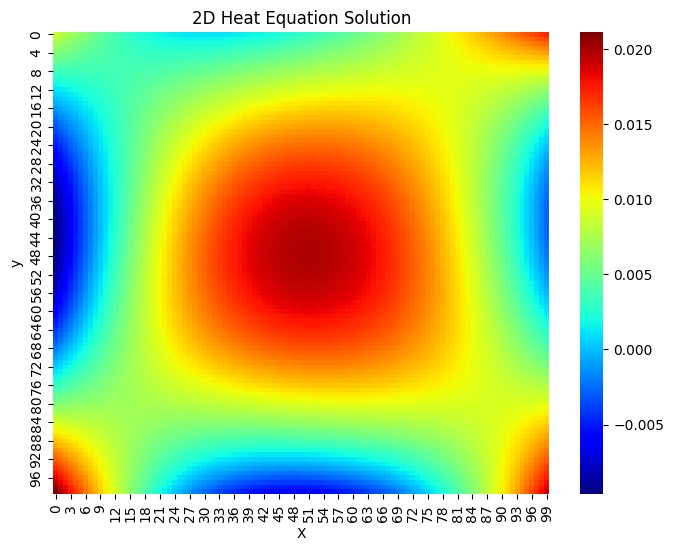

In [47]:
with torch.no_grad():
    x_vals = torch.linspace(0,1,100)
    y_vals = torch.linspace(0,1,100)
    X, Y = torch.meshgrid(x_vals, y_vals)
    t_val = torch.ones_like(X) * 0.2 # specify the time

    input_data = torch.stack([X.flatten(),Y.flatten(), t_val.flatten()], dim=1)
    solution = model(input_data).reshape(X.shape, Y.shape)

    plt.figure(figsize=(8,6))
    sns.heatmap(solution, cmap="jet")
    plt.title("2D Heat Equation Solution")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.show()

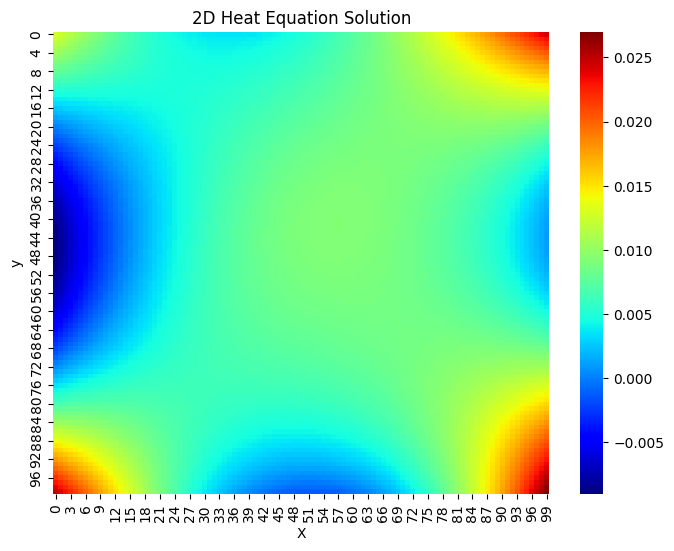

In [48]:
with torch.no_grad():
    x_vals = torch.linspace(0,1,100)
    y_vals = torch.linspace(0,1,100)
    X, Y = torch.meshgrid(x_vals, y_vals)
    t_val = torch.ones_like(X) * 0.25 # specify the time

    input_data = torch.stack([X.flatten(),Y.flatten(), t_val.flatten()], dim=1)
    solution = model(input_data).reshape(X.shape, Y.shape)

    plt.figure(figsize=(8,6))
    sns.heatmap(solution, cmap="jet")
    plt.title("2D Heat Equation Solution")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.show()

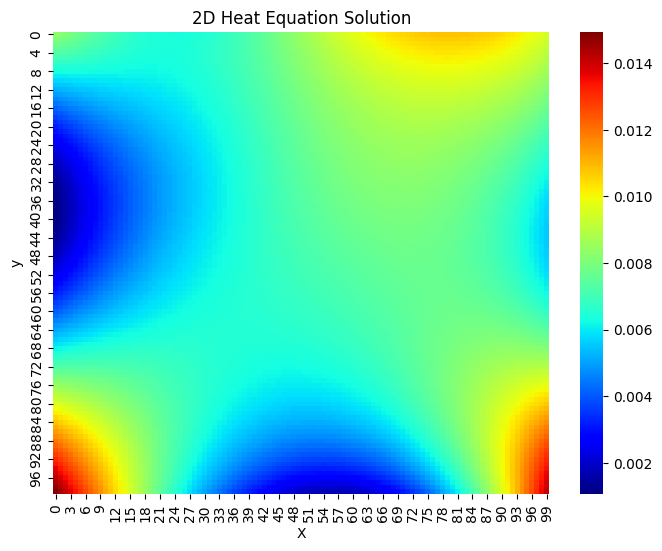

In [49]:
with torch.no_grad():
    x_vals = torch.linspace(0,1,100)
    y_vals = torch.linspace(0,1,100)
    X, Y = torch.meshgrid(x_vals, y_vals)
    t_val = torch.ones_like(X) * 0.5 # specify the time

    input_data = torch.stack([X.flatten(),Y.flatten(), t_val.flatten()], dim=1)
    solution = model(input_data).reshape(X.shape, Y.shape)

    plt.figure(figsize=(8,6))
    sns.heatmap(solution, cmap="jet")
    plt.title("2D Heat Equation Solution")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.show()

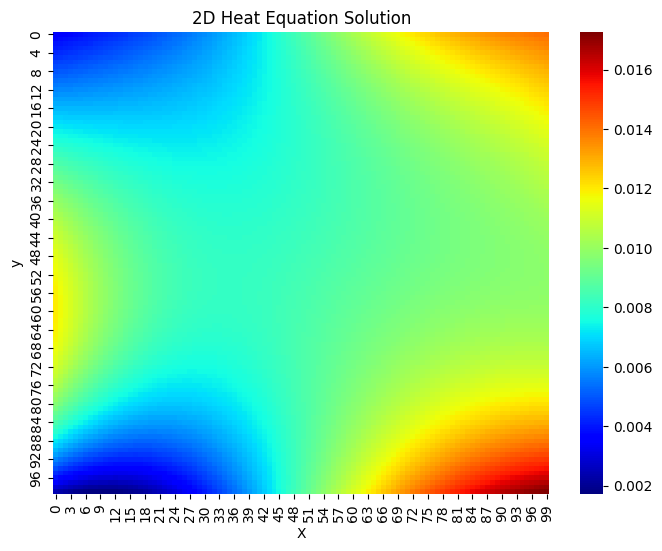

In [50]:
with torch.no_grad():
    x_vals = torch.linspace(0,1,100)
    y_vals = torch.linspace(0,1,100)
    X, Y = torch.meshgrid(x_vals, y_vals)
    t_val = torch.ones_like(X) * 1 # specify the time

    input_data = torch.stack([X.flatten(),Y.flatten(), t_val.flatten()], dim=1)
    solution = model(input_data).reshape(X.shape, Y.shape)

    plt.figure(figsize=(8,6))
    sns.heatmap(solution, cmap="jet")
    plt.title("2D Heat Equation Solution")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.show()